

# Dipolo de fio fino


Fio PEC reto no eixo z, comprimento L, raio a << L, alimentado no centro por um delta-gap de $V_0 = 1$ V. Queremos descobrir a corrente $I(z)$.

<br>

<p align="center">
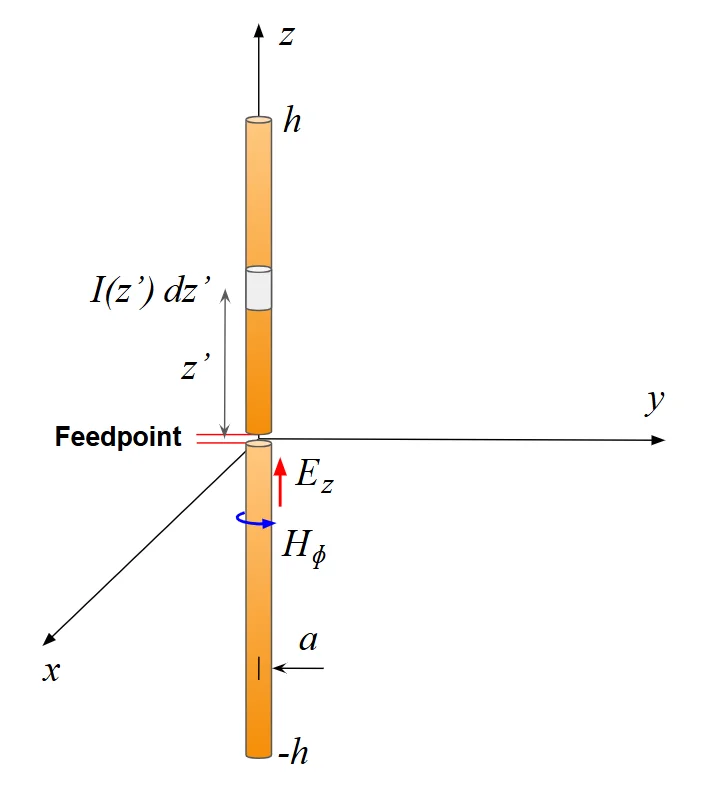
</p>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

In [ ]:
c0   = 299792458 # velocidade da luz (vácuo)
mu0  = 4e-7 * np.pi # permeabilidade (vácuo)
eps0 = 1 / (mu0 * c0**2) # permissividade (vácuo)

lam   = 1.0 # comprimento de onda
f     = c0 / lam # frequência
omega = 2 * np.pi * f # frequência angular
k     = 2 * np.pi / lam # número de onda

L  = 0.5 * lam # comprimento total
a  = 1e-3 * lam # raio do fio
V0 = 1.0 # tensão do delta-gap

Cortamos o fio, que vai de L/2 a L/2, emN segmentos iguais de comprimento Delta = L/N. Isso gera N + 1 bordas e N centros.

<br>

Com  N ímpar, o segmento do meio fica centrado em z = 0 (delta-gap).

<br>

As funções de base serão as funções de pulso, sendo constante em cada segmento, igual a $I_n$ no segmento n e zero fora dele:

<br>

$$
I(z) \approx \sum_{n=1}^{N} I_n\, f_n(z), \qquad f_n(z) = \begin{cases} 1, & \text{z no segmento n} \\ 0, & \text{fora} \end{cases}
$$

<br>

A EFIE é imposta somente nos centros dos segmentos: N equações para N incógnitas.

In [ ]:
def segmentos_fio(L, N): # divide o fio [-L/2, L/2] em N segmentos iguais
    z_bordas = np.linspace(-L/2, L/2, N + 1) # N+1 bordas = pontas dos pulsos
    zc = (z_bordas[:-1] + z_bordas[1:]) / 2 # N centros = pontos de colocação
    return z_bordas, zc

Fora da diagonal, a matriz precisa de $\int e^{-jkR}/R\,dz'$. Usa-se Gauss-Legendre para resolver.

In [ ]:
M = 5 # pontos de Gauss por segmento (tirados do livro do Walton)
xg, wg = np.polynomial.legendre.leggauss(M) # pontos e pesos em [-1, 1]

def gauss_segmento(z1, z2): # pontos e pesos levados para o segmento [z1, z2]
    meio, metade = (z1 + z2) / 2, (z2 - z1) / 2
    return meio + metade * xg, metade * wg # returna 5 pontos e 5 pesos

Usando o método da colocação, a EFIE é cobrada só nos centros dos segmentos, $z_1, \ldots, z_N$.

<br>

Em cada centro $z_m$, o campo que as correntes de todos os segmentos produzem tem que cancelar o campo da fonte. O campo que o segmento $n$ produz em $z_m$ é $Z_{mn}\, I_n$. Somando os $N$ segmentos:

<br>

$$
\sum_{n=1}^{N} Z_{mn}\, I_n = V_m
$$

<br>

$V_m$ é o campo da fonte em $z_m$. O delta-gap aplica $V_0$ numa fenda de largura $\Delta$, então o campo vale $V_0/\Delta$ no segmento do meio e zero nos outros.

<br>

A EFIE tem o operador $\left(1 + \frac{1}{k^2}\frac{\partial^2}{\partial z^2}\right)$ aplicado à integral da corrente. Com a corrente constante no segmento $n$, a integral fica só sobre esse segmento, e $Z_{mn}$ sai em duas parcelas:

<br>

$$
Z_{mn} = \frac{j\omega\mu}{4\pi}\int_{z_n - \Delta/2}^{z_n + \Delta/2}\frac{e^{-jkR}}{R}\,dz' + \frac{j}{4\pi\omega\varepsilon}\left[(z_m - z')\,\frac{1 + jkR}{R^3}\,e^{-jkR}\right]_{z' = z_n - \Delta/2}^{z' = z_n + \Delta/2}
$$

<br>

A primeira parcela é o termo 1, a segunda é o termo 2.

<br>

Com R sendo a distância entre o ponto z' do segmento n e o ponto $z_m$ :

$$
R = \left[(z_m - z')^2 + a^2\right]^{1/2}
$$

<br>

O termo 1 é a soma das contribuições de cada pedacinho do segmento n no ponto $z_m$. Cada pedacinho contribui com $e^{-jkR}/R$.

<br>

Fora da diagonal (m ≠ n), o ponto está fora do segmento e a contribuição varia devagar ao longo dele, usamos Gauss-Legendre para resolver.

<br>

Na diagonal (m = n), o ponto está no meio do próprio segmento, a distância cai para R = a, e 1/R. Mas aqui R é pequeno em todo o segmento, então vale a aproximação $e^{-jkR} \approx 1 - jkR$ e a integral sai analiticamente:

<br>

$$
\int_{-\Delta/2}^{\Delta/2}\frac{e^{-jkR}}{R}\,dz' \approx \ln\left(\frac{s + 1}{s - 1}\right) - jk\Delta, \qquad s = \left[1 + \frac{4a^2}{\Delta^2}\right]^{1/2}
$$

<br>

$Z_{mn}$ só depende da distância entre $z_m$ e $z_n$, então cada diagonal da matriz tem um único valor e a matriz é Toeplitz. Em vez de calcular $N^2$ elementos, calcula-se uma coluna só, com o ponto no centro do primeiro segmento e a fonte em cada um dos $N$ segmentos.

In [ ]:
def green_3D(zo, zf): # e^{-jkR}/R entre um ponto de observação zo e um ponto de fonte zf
    R = np.sqrt((zo - zf)**2 + a**2)
    return np.exp(-1j * k * R) / R

def expressao_termo_2(zo, zf): # expressao do termo 2
    R = np.sqrt((zo - zf)**2 + a**2)
    return (zo - zf) * (1 + 1j * k * R) * np.exp(-1j * k * R) / R**3

def coluna_point_matching(z_bordas, zc, dl):
    zm = zc[0] # ponto de observação fixo no centro do primeiro segmento

    z_inicio = z_bordas[:-1] # início de cada segmento, vetor N
    z_fim    = z_bordas[1:] # fim de cada segmento, vetor N

    # termo 1, fora da diagonal, Gauss em cada segmento
    zq, wq = gauss_segmento(z_inicio[:, None], z_fim[:, None]) # 5 pontos e 5 pesos por segmento, matrizes (N, 5)
    termo1 = 1j * omega * mu0 * np.sum(wq * green_3D(zm, zq), axis=1) # um valor por segmento, vetor N

    # termo 1, diagonal, fórmula analítica
    s = np.sqrt(1 + 4 * a**2 / dl**2)
    termo1[0] = 1j * omega * mu0 * (np.log((s + 1) / (s - 1)) - 1j * k * dl)

    # termo 2, expressão nas duas pontas de cada segmento
    termo2 = 1j / (omega * eps0) * (expressao_termo_2(zm, z_fim) - expressao_termo_2(zm, z_inicio))

    # primeira coluna da matriz que será repetida nas diagonais
    return (termo1 + termo2) / (4 * np.pi)

def fonte_point_matching(z_bordas, zc): # delta-gap no segmento do meio
    N  = len(zc)
    dl = z_bordas[1] - z_bordas[0]
    V = np.zeros(N) # fora da fenda o campo é zero
    V[N // 2] = V0 / dl # segmento do meio
    return V

Com Z e V montados, resolve-se ZI = V por LU com método direto. O resultado I é a corrente em cada um dos N segmentos.

<br>

A impedância de entrada é a tensão da fonte dividida pela corrente no ponto de alimentação, o segmento do meio:

<br>

$$
Z_{\text{in}} = \frac{V_0}{I_{N/2}}
$$

Zin = 83.7+28.9j


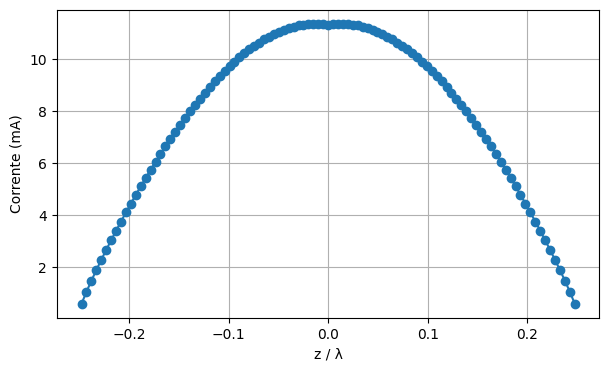

In [ ]:
N_discretizacao = 101 # discretização em N pontos
z_bordas, z_centro = segmentos_fio(L, N_discretizacao)
dl = L / N_discretizacao

coluna = coluna_point_matching(z_bordas, z_centro, dl)

Z = toeplitz(coluna, coluna) # matriz cheia
V = fonte_point_matching(z_bordas, z_centro)

I = np.linalg.solve(Z, V) # corrente em cada segmento, vetor N
Zin = V0 / I[N_discretizacao // 2] # tensão da fonte sobre a corrente do segmento do meio
print(f"Zin = {Zin:.1f}")

plt.figure(figsize=(7, 4))
plt.plot(z_centro / lam, np.abs(I) * 1e3, 'o-')
plt.xlabel('z / λ')
plt.ylabel('Corrente (mA)')
plt.grid(True)
plt.show()

Para resolver ZI = V sem fatorar a matriz, usamos o gradiente conjugado nas equações normais. O sistema resolvido é:

<br>

$$
\mathbf{Z}^{h}\mathbf{Z}\,\mathbf{I} = \mathbf{Z}^{h}\mathbf{V}
$$
com $\mathbf{Z}^{h}$ a transposta conjugada de Z. A solução é a mesma do sistema original. A cada iteração a estimativa de $\mathbf{I}$ é corrigida numa direção $\mathbf{p}$:

<br>

$$
\mathbf{I}_{k+1} = \mathbf{I}_k + \alpha_k\,\mathbf{p}_k
$$

<br>

O custo de cada iteração são dois produtos matriz-vetor, um com Z e um com $\mathbf{Z}^{h}$.

CG: 76 iterações, Zin = 83.7+28.9j Ω


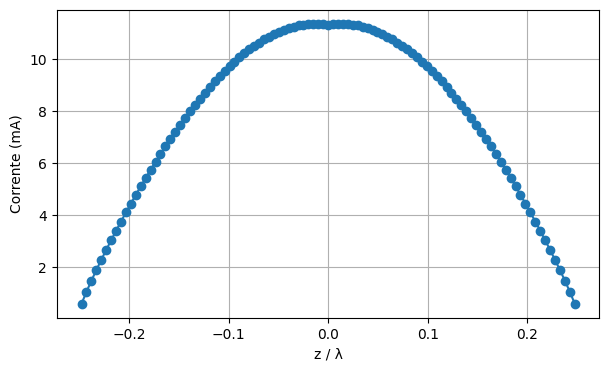

In [ ]:
def produto_matriz(x): # Z x com a matriz cheia
    return Z @ x

def produto_matriz_H(x): # Z^H x com a matriz cheia
    return Z.conj().T @ x

def cg(produto, produto_H, b, tol): # CGNR com M = I
    N = len(b)

    x  = np.zeros(N) # chute inicial x0 = 0
    r  = b - produto(x) # r0 = b - Ax0
    r_linha = produto_H(r) # r~0 = A^Hr0
    z  = r_linha # Mz0 = r~0, com M = I
    p  = z.copy() # p0 = z0

    residuos = []
    for i in range(N):
        w = produto(p) # w = Ap
        alpha = np.vdot(z, r_linha) / np.vdot(w, w) # (z* . r~) / ||w||²
        x = x + alpha * p # x = x + alphap
        r = r - alpha * w # r = r - alphap

        residuos.append(np.linalg.norm(r) / np.linalg.norm(b))
        if residuos[-1] < tol: # ultimo resíduo menor que tolerância
            break

        r_linha_novo = produto_H(r) # r~ = A^H r
        z_novo  = r_linha_novo # M = I
        beta = np.vdot(z_novo, r_linha_novo) / np.vdot(z, r_linha) # (z*_i . r~_i) / (z*_{i-1} . r~_{i-1})
        p = z_novo + beta * p
        z, r_linha = z_novo, r_linha_novo

    return x, residuos

I_cg, residuos = cg(produto_matriz, produto_matriz_H, V, tol=1e-3)
print(f"CG: {len(residuos)} iterações, Zin = {V0 / I_cg[N_discretizacao // 2]:.1f} Ω")

plt.figure(figsize=(7, 4))
plt.plot(z_centro / lam, np.abs(I_cg) * 1e3, 'o-')
plt.xlabel('z / λ')
plt.ylabel('Corrente (mA)')
plt.grid(True)
plt.show()

A cada iteração o CG faz dois produtos matriz-vetor. Com a matriz cheia, cada produto custa $N^2$ operações e com armazenamento também de $N^2$.

<br>

Como Z é Toeplitz, Zx é uma convolução discreta:

<br>

$$
y_m = \sum_{n=1}^{N} Z_{m-n}\, x_n
$$

<br>

e convolução vira multiplicação ponto a ponto no domínio da frequência.

<br>

$$
\mathbf{y} = \text{FFT}^{-1}\left[\text{FFT}(\mathbf{Z}) \odot \text{FFT}(\mathbf{x})\right]
$$

<br>

Os primeiros $N$ elementos de y são Zx. Custo $N\log N$ em vez de $N^2$, e só a coluna fica na memória.

CG-FFT: 75 iterações, Zin = 83.7+28.9j Ω


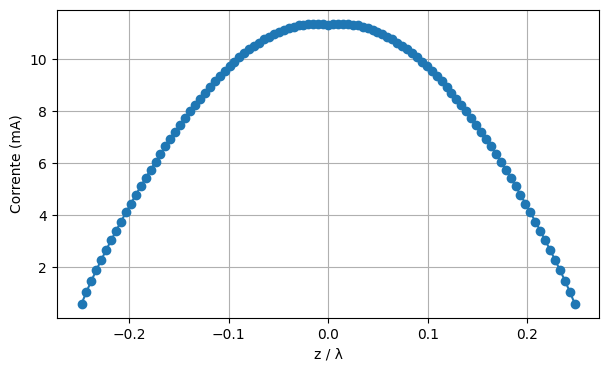

In [ ]:
def produto_fft(x): # Z x usando só a coluna, via FFT
    N = len(x)
    Z_ext = np.concatenate([coluna, coluna[-1:0:-1]]) # coluna espelhada, tamanho 2N-1
    x_ext = np.concatenate([x, np.zeros(N - 1)]) # x completado com zeros até 2N-1
    y_ext = np.fft.ifft(np.fft.fft(Z_ext) * np.fft.fft(x_ext)) # convolução
    return y_ext[:N] # os N primeiros elementos são Z x

def produto_fft_H(x): # Z^H x, pela simetria de Z
    return np.conj(produto_fft(np.conj(x)))

I_fft, residuos = cg(produto_fft, produto_fft_H, V, tol=1e-3)
print(f"CG-FFT: {len(residuos)} iterações, Zin = {V0 / I_fft[N_discretizacao // 2]:.1f} Ω")

plt.figure(figsize=(7, 4))
plt.plot(z_centro / lam, np.abs(I_fft) * 1e3, 'o-')
plt.xlabel('z / λ')
plt.ylabel('Corrente (mA)')
plt.grid(True)
plt.show()